In [55]:
##202431007_Wijdan Zayyan Sururi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
##202431007_Wijdan Zayyan Sururi
data_km = pd.read_csv('food_delivery.csv')
data_knn = pd.read_csv('ai_student_impact_dataset (1).csv')
data_svm = pd.read_csv('campus_ai_pulse_2026.csv')
print(data_km.shape, data_knn.shape, data_svm.shape)

(8000, 26) (50000, 16) (1200, 24)


In [57]:
##202431007_Wijdan Zayyan Sururi
data_km.head()

,order_id,metro_city,cuisine_category,order_channel,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,...,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,customer_spending_tier,logistics_friction_index,estimated_restaurant_net_margin_usd,customer_satisfaction_tier,primary_satisfaction_driver,cot_market_dynamics_rationale,confidence_score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


In [58]:
##202431007_Wijdan Zayyan Sururi
data_km.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   object 
 1   metro_city                           8000 non-null   object 
 2   cuisine_category                     8000 non-null   object 
 3   order_channel                        8000 non-null   object 
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier         

In [59]:
##202431007_Wijdan Zayyan Sururi
data_km.describe()

,order_value_usd,discount_applied_usd,delivery_distance_km,estimated_prep_time_min,actual_delivery_time_min,delivery_fee_usd,customer_rating,net_effective_order_price,discount_percentage,delivery_speed_km_per_hr,total_fulfillment_time_min,delivery_fee_ratio,logistics_friction_index,estimated_restaurant_net_margin_usd,confidence_score
count,8000.000000,8000.000000,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.222839,3.328607,3.048638,18.04200,11.272588,2.962597,4.281375,29.856829,11.911265,10.287050,29.314588,0.184009,2.251100,10.789798,0.987976
std,26.366910,5.183003,3.937749,6.76934,13.533084,2.672989,0.647210,24.372821,12.115306,9.335752,16.210216,0.270723,1.624059,10.667783,0.002500
min,3.500000,0.000000,0.000000,5.00000,0.000000,0.000000,1.000000,2.300000,0.000000,0.000000,5.000000,0.000000,0.200000,-0.210000,0.953000
25%,12.920000,0.000000,0.000000,13.00000,0.000000,0.000000,4.000000,14.040000,0.000000,0.000000,18.000000,0.000000,0.850000,3.727500,0.988000
50%,21.705000,1.530000,1.600000,18.00000,8.000000,2.970000,4.500000,22.310000,9.535000,10.500000,26.000000,0.100850,2.190000,7.440000,0.989000
75%,37.892500,4.440000,4.500000,22.00000,15.200000,4.540000,5.000000,37.235000,23.022500,17.050000,36.700000,0.249425,3.300000,13.912500,0.989000
max,145.000000,35.000000,22.000000,49.00000,75.000000,9.500000,5.000000,154.500000,35.020000,57.000000,111.000000,2.714300,8.920000,67.850000,0.990000


In [60]:
##202431007_Wijdan Zayyan Sururi
data_knn.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [61]:
##202431007_Wijdan Zayyan Sururi
data_knn.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

In [62]:
##202431007_Wijdan Zayyan Sururi
data_knn.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [63]:
##202431007_Wijdan Zayyan Sururi
data_svm.head()

,student_id,age,gender,country,university_type,program,year_of_study,uni_ai_policy,uses_ai,primary_ai_tool,...,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,ai_dependency_level,integrity_concern_level,flagged_by_ai_detector,would_recommend_ai
0,S0001,20,Female,India,Public,Engineering,2,Allowed,Yes,ChatGPT,...,51,13.7,2.88,53,47,8,High,3,Yes,No
1,S0002,22,Male,Nigeria,Private,Computer Science,2,No clear policy,Yes,ChatGPT,...,11,19.8,3.52,84,29,2,Low,3,No,Yes
2,S0003,21,Male,United States,Private,Business,4,Allowed with disclosure,Yes,Perplexity,...,11,20.4,2.94,72,20,2,Low,3,No,Yes
3,S0004,22,Female,Bangladesh,Private,Medicine & Health,3,No clear policy,Yes,Claude,...,46,18.0,2.70,68,23,6,Medium,1,No,Yes
4,S0005,20,Male,Bangladesh,Private,Natural Sciences,1,Allowed,Yes,ChatGPT,...,9,24.8,3.01,62,19,3,Low,1,No,No


In [64]:
##202431007_Wijdan Zayyan Sururi
data_svm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   student_id               1200 non-null   object 
 1   age                      1200 non-null   int64  
 2   gender                   1200 non-null   object 
 3   country                  1200 non-null   object 
 4   university_type          1200 non-null   object 
 5   program                  1200 non-null   object 
 6   year_of_study            1200 non-null   int64  
 7   uni_ai_policy            1200 non-null   object 
 8   uses_ai                  1200 non-null   object 
 9   primary_ai_tool          1200 non-null   object 
 10  primary_use_case         1200 non-null   object 
 11  ai_hours_per_week        1200 non-null   float64
 12  paid_ai_subscription     1200 non-null   object 
 13  prompt_skill_level       1200 non-null   int64  
 14  ai_assignment_share_pct 

In [65]:
##202431007_Wijdan Zayyan Sururi
data_svm.describe()

,age,year_of_study,ai_hours_per_week,prompt_skill_level,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,integrity_concern_level
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,20.115833,2.286667,5.882417,2.485833,25.779167,17.700333,3.040325,61.670000,21.722500,4.220000,3.079167
std,1.433805,1.085728,4.604273,1.233315,17.892797,4.322299,0.377610,11.473991,12.767981,2.619921,1.053007
min,18.000000,1.000000,0.000000,0.000000,0.000000,3.400000,1.870000,28.000000,0.000000,1.000000,1.000000
25%,19.000000,1.000000,2.600000,2.000000,13.000000,14.700000,2.790000,54.000000,14.000000,2.000000,2.000000
50%,20.000000,2.000000,5.150000,3.000000,25.000000,17.650000,3.030000,61.000000,23.000000,4.000000,3.000000
75%,21.000000,3.000000,8.300000,3.000000,36.250000,20.800000,3.300000,70.000000,30.000000,6.000000,4.000000
max,24.000000,4.000000,31.600000,5.000000,99.000000,33.200000,4.000000,100.000000,64.000000,10.000000,5.000000


In [66]:
##202431007_Wijdan Zayyan Sururi
df_km = data_km.copy()
print('NaN sebelum dibersihkan')
print(df_km.isna().sum())

df_km = df_km.drop(columns=['order_id', 'cot_market_dynamics_rationale'])
df_km = df_km.fillna(df_km.median(numeric_only=True))
for kolom in df_km.select_dtypes(exclude='number').columns:
    df_km[kolom] = df_km[kolom].fillna(df_km[kolom].mode()[0])
df_km = df_km.drop_duplicates().reset_index(drop=True)

print('NaN sesudah dibersihkan')
print(df_km.isna().sum())
print(data_km.shape, df_km.shape)

NaN sebelum dibersihkan
order_id                               0
metro_city                             0
cuisine_category                       0
order_channel                          0
order_value_usd                        0
discount_applied_usd                   0
delivery_distance_km                   0
estimated_prep_time_min                0
actual_delivery_time_min               0
delivery_fee_usd                       0
customer_rating                        0
restaurant_price_tier                  0
is_peak_hour                           0
weather_condition                      0
net_effective_order_price              0
discount_percentage                    0
delivery_speed_km_per_hr               0
total_fulfillment_time_min             0
delivery_fee_ratio                     0
customer_spending_tier                 0
logistics_friction_index               0
estimated_restaurant_net_margin_usd    0
customer_satisfaction_tier             0
primary_satisfaction_driver      

In [67]:
##202431007_Wijdan Zayyan Sururi
df_knn = data_knn.copy()
print('NaN sebelum dibersihkan')
print(df_knn.isna().sum())

df_knn = df_knn.drop(columns=['Student_ID'])
df_knn = df_knn.fillna(df_knn.median(numeric_only=True))
for kolom in df_knn.select_dtypes(exclude='number').columns:
    df_knn[kolom] = df_knn[kolom].fillna(df_knn[kolom].mode()[0])
df_knn = df_knn.drop_duplicates().reset_index(drop=True)

print('NaN sesudah dibersihkan')
print(df_knn.isna().sum())
print(data_knn.shape, df_knn.shape)

NaN sebelum dibersihkan
Student_ID                    0
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Retention_Score         0
Burnout_Risk_Level            0
dtype: int64
NaN sesudah dibersihkan
Major_Category                0
Year_of_Study                 0
Pre_Semester_GPA              0
Weekly_GenAI_Hours            0
Primary_Use_Case              0
Prompt_Engineering_Skill      0
Tool_Diversity                0
Paid_Subscription             0
Traditional_Study_Hours       0
Perceived_AI_Dependency       0
Institutional_Policy          0
Anxiety_Level_During_Exams    0
Post_Semester_GPA             0
Skill_Reten

In [68]:
##202431007_Wijdan Zayyan Sururi
df_svm = data_svm.copy()
print('NaN sebelum dibersihkan')
print(df_svm.isna().sum())

df_svm = df_svm.drop(columns=['student_id'])
df_svm = df_svm.fillna(df_svm.median(numeric_only=True))
for kolom in df_svm.select_dtypes(exclude='number').columns:
    df_svm[kolom] = df_svm[kolom].fillna(df_svm[kolom].mode()[0])
df_svm = df_svm.drop_duplicates().reset_index(drop=True)

print('NaN sesudah dibersihkan')
print(df_svm.isna().sum())
print(data_svm.shape, df_svm.shape)

NaN sebelum dibersihkan
student_id                 0
age                        0
gender                     0
country                    0
university_type            0
program                    0
year_of_study              0
uni_ai_policy              0
uses_ai                    0
primary_ai_tool            0
primary_use_case           0
ai_hours_per_week          0
paid_ai_subscription       0
prompt_skill_level         0
ai_assignment_share_pct    0
study_hours_per_week       0
cgpa                       0
critical_thinking_score    0
time_saved_pct             0
ai_dependency_score        0
ai_dependency_level        0
integrity_concern_level    0
flagged_by_ai_detector     0
would_recommend_ai         0
dtype: int64
NaN sesudah dibersihkan
age                        0
gender                     0
country                    0
university_type            0
program                    0
year_of_study              0
uni_ai_policy              0
uses_ai                    0
primary_ai_

## 4.1 K-Means Clustering

In [69]:
##202431007_Wijdan Zayyan Sururi
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [70]:
##202431007_Wijdan Zayyan Sururi
fitur_km = ['order_value_usd', 'delivery_distance_km', 'total_fulfillment_time_min']
x_km = df_km[fitur_km]
print(x_km.corr().round(3))

                            order_value_usd  delivery_distance_km  \
order_value_usd                       1.000                -0.017   
delivery_distance_km                 -0.017                 1.000   
total_fulfillment_time_min           -0.018                 0.814   

                            total_fulfillment_time_min  
order_value_usd                                 -0.018  
delivery_distance_km                             0.814  
total_fulfillment_time_min                       1.000  


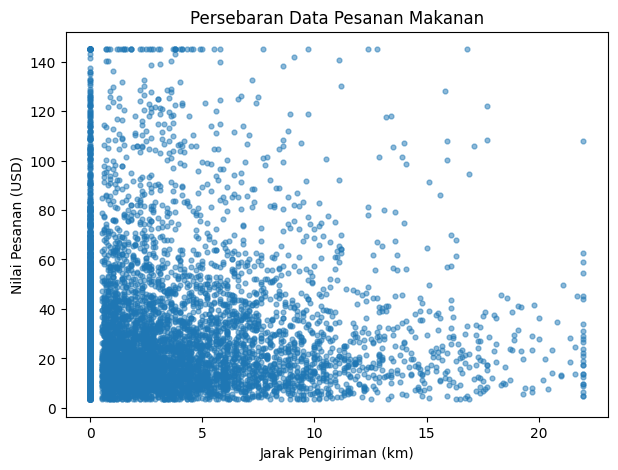

In [71]:
##202431007_Wijdan Zayyan Sururi
plt.figure(figsize=(7, 5))
plt.scatter(x_km['delivery_distance_km'], x_km['order_value_usd'], s=12, alpha=0.5)
plt.title('Persebaran Data Pesanan Makanan')
plt.xlabel('Jarak Pengiriman (km)')
plt.ylabel('Nilai Pesanan (USD)')
plt.show()

In [72]:
##202431007_Wijdan Zayyan Sururi
scaler_km = StandardScaler()
x_km_scaled = scaler_km.fit_transform(x_km)

print(pd.DataFrame({'mean': x_km_scaled.mean(axis=0),
                    'std': x_km_scaled.std(axis=0)}, index=fitur_km).round(4))

                            mean  std
order_value_usd              0.0  1.0
delivery_distance_km        -0.0  1.0
total_fulfillment_time_min  -0.0  1.0


In [73]:
##202431007_Wijdan Zayyan Sururi
wcss = []
for i in range(1, 11):
    kmModel = KMeans(n_clusters=i, n_init=10, random_state=0)
    kmModel.fit(x_km_scaled)
    wcss.append(kmModel.inertia_)
print(np.round(wcss, 2))

[24000.   14544.41  9783.99  7419.15  6320.54  5297.    4799.55  4388.25
  4033.43  3745.08]


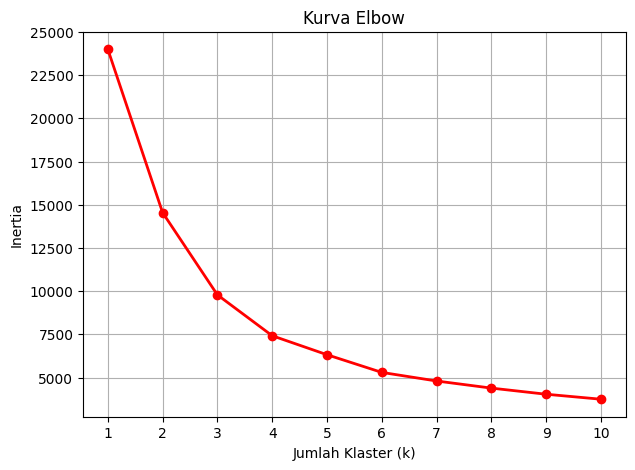

In [74]:
##202431007_Wijdan Zayyan Sururi
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), wcss, marker='o', color='red', linewidth=2)
plt.title('Kurva Elbow')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [25]:
##202431007_Wijdan Zayyan Sururi
hasil_eval = []
for k in range(2, 7):
    label_k = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(x_km_scaled)
    sil = silhouette_score(x_km_scaled, label_k)
    dbi = davies_bouldin_score(x_km_scaled, label_k)
    hasil_eval.append([k, round(sil, 4), round(dbi, 4)])

tabel_eval = pd.DataFrame(hasil_eval, columns=['k', 'Silhouette', 'DBI'])
print(tabel_eval.to_string(index=False))
print('Silhouette: makin tinggi makin baik | DBI: makin rendah makin baik')

 k  Silhouette    DBI
 2      0.4705 0.9414
 3      0.4701 0.8278
 4      0.3830 0.9061
 5      0.3286 0.9988
 6      0.3389 0.9505
Silhouette: makin tinggi makin baik | DBI: makin rendah makin baik


In [26]:
##202431007_Wijdan Zayyan Sururi
k_final = 3
kmModelFix = KMeans(n_clusters=k_final, n_init=10, random_state=0)
hasil_prediksi = kmModelFix.fit_predict(x_km_scaled)

print(pd.DataFrame(kmModelFix.cluster_centers_, columns=fitur_km).round(4))
print(pd.Series(hasil_prediksi).value_counts().sort_index())

   order_value_usd  delivery_distance_km  total_fulfillment_time_min
0          -0.3303               -0.3928                     -0.3665
1          -0.1724                1.6470                      1.5322
2           2.0982               -0.2642                     -0.2398
0    5526
1    1479
2     995
Name: count, dtype: int64


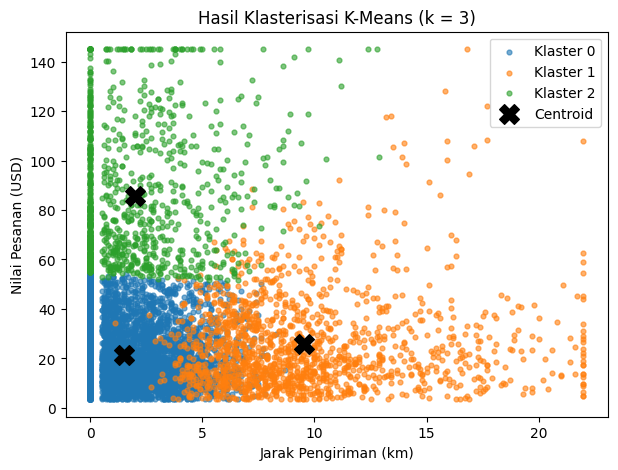

In [27]:
##202431007_Wijdan Zayyan Sururi
pusat_asli = scaler_km.inverse_transform(kmModelFix.cluster_centers_)

plt.figure(figsize=(7, 5))
for i in range(k_final):
    plt.scatter(df_km.loc[hasil_prediksi == i, 'delivery_distance_km'],
                df_km.loc[hasil_prediksi == i, 'order_value_usd'],
                s=12, alpha=0.6, label='Klaster ' + str(i))
plt.scatter(pusat_asli[:, 1], pusat_asli[:, 0], c='black', s=200, marker='X', label='Centroid')
plt.title('Hasil Klasterisasi K-Means (k = 3)')
plt.xlabel('Jarak Pengiriman (km)')
plt.ylabel('Nilai Pesanan (USD)')
plt.legend()
plt.show()

In [28]:
##202431007_Wijdan Zayyan Sururi
df_km['klaster'] = hasil_prediksi
profil = df_km.groupby('klaster')[fitur_km].mean().round(2)
profil['jumlah'] = df_km['klaster'].value_counts().sort_index()
print(profil)

         order_value_usd  delivery_distance_km  total_fulfillment_time_min  \
klaster                                                                      
0                  21.50                  1.50                       23.37   
1                  25.68                  9.53                       54.13   
2                  85.44                  2.02                       25.45   

         jumlah  
klaster          
0          5526  
1          1479  
2           995  


In [29]:
##202431007_Wijdan Zayyan Sururi
id_tinggi = profil['order_value_usd'].idxmax()
sisa = profil.drop(index=id_tinggi)
id_jauh = sisa['delivery_distance_km'].idxmax()
id_dekat = sisa['delivery_distance_km'].idxmin()

nama_klaster = {id_tinggi: 'Pesanan Bernilai Tinggi',
                id_jauh: 'Pengiriman Jauh dan Lama',
                id_dekat: 'Pesanan Reguler Dekat dan Cepat'}
profil['nama'] = profil.index.map(nama_klaster)
print(profil)

         order_value_usd  delivery_distance_km  total_fulfillment_time_min  \
klaster                                                                      
0                  21.50                  1.50                       23.37   
1                  25.68                  9.53                       54.13   
2                  85.44                  2.02                       25.45   

         jumlah                             nama  
klaster                                           
0          5526  Pesanan Reguler Dekat dan Cepat  
1          1479         Pengiriman Jauh dan Lama  
2           995          Pesanan Bernilai Tinggi  


In [30]:
##202431007_Wijdan Zayyan Sururi
print('DBI        :', round(davies_bouldin_score(x_km_scaled, hasil_prediksi), 4))
print('Silhouette :', round(silhouette_score(x_km_scaled, hasil_prediksi), 4))

DBI        : 0.8278
Silhouette : 0.4701


## 4.2 K-Nearest Neighbors (KNN)

In [31]:
##202431007_Wijdan Zayyan Sururi
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [32]:
##202431007_Wijdan Zayyan Sururi
print(df_knn['Prompt_Engineering_Skill'].value_counts())
print(df_knn['Prompt_Engineering_Skill'].value_counts(normalize=True).round(3))

# Beginner     = kemampuan prompt dasar
# Intermediate = kemampuan prompt menengah
# Advanced     = kemampuan prompt mahir

Prompt_Engineering_Skill
Beginner        18495
Intermediate    17696
Advanced        13809
Name: count, dtype: int64
Prompt_Engineering_Skill
Beginner        0.370
Intermediate    0.354
Advanced        0.276
Name: proportion, dtype: float64


In [33]:
##202431007_Wijdan Zayyan Sururi
df_knn['Paid_Subscription'] = df_knn['Paid_Subscription'].astype(int)
df_knn['Burnout_Risk_Level'] = df_knn['Burnout_Risk_Level'].map({'Low': 0, 'Medium': 1, 'High': 2})

x_knn = df_knn.drop(columns=['Prompt_Engineering_Skill', 'Major_Category', 'Year_of_Study',
                             'Primary_Use_Case', 'Institutional_Policy'])
y_knn = df_knn['Prompt_Engineering_Skill']
print(x_knn.dtypes)

Pre_Semester_GPA              float64
Weekly_GenAI_Hours            float64
Tool_Diversity                  int64
Paid_Subscription               int64
Traditional_Study_Hours       float64
Perceived_AI_Dependency         int64
Anxiety_Level_During_Exams      int64
Post_Semester_GPA             float64
Skill_Retention_Score         float64
Burnout_Risk_Level              int64
dtype: object


In [34]:
##202431007_Wijdan Zayyan Sururi
x_train_knn, x_test_knn, y_train_knn, y_test_knn = train_test_split(
    x_knn, y_knn, test_size=0.25, random_state=0, stratify=y_knn)

print('Data latih:', x_train_knn.shape[0])
print('Data uji  :', x_test_knn.shape[0])

Data latih: 37500
Data uji  : 12500


In [35]:
##202431007_Wijdan Zayyan Sururi
rentang = pd.DataFrame({'min': x_train_knn.min(), 'max': x_train_knn.max()})
rentang['lebar'] = rentang['max'] - rentang['min']
print(rentang.round(3))
print('Rentang terlebar:', rentang['lebar'].idxmax())

                               min      max   lebar
Pre_Semester_GPA             1.183    3.998   2.815
Weekly_GenAI_Hours           0.000   40.000  40.000
Tool_Diversity               1.000    5.000   4.000
Paid_Subscription            0.000    1.000   1.000
Traditional_Study_Hours      1.000   31.210  30.210
Perceived_AI_Dependency      1.000   10.000   9.000
Anxiety_Level_During_Exams   1.000   10.000   9.000
Post_Semester_GPA            1.000    4.000   3.000
Skill_Retention_Score       10.780  100.000  89.220
Burnout_Risk_Level           0.000    2.000   2.000
Rentang terlebar: Skill_Retention_Score


In [36]:
##202431007_Wijdan Zayyan Sururi
pipeline_knn = Pipeline([('scaler', StandardScaler()),
                         ('knn', KNeighborsClassifier())])

In [37]:
##202431007_Wijdan Zayyan Sururi
params_knn = {'knn__n_neighbors': list(range(1, 20))}

grid_knn = GridSearchCV(pipeline_knn, params_knn, cv=5, scoring='accuracy', n_jobs=-1)
grid_knn.fit(x_train_knn, y_train_knn)

print('k terbaik           :', grid_knn.best_params_['knn__n_neighbors'])
print('Skor validasi silang:', round(grid_knn.best_score_, 4))

k terbaik           : 18
Skor validasi silang: 0.5507


In [38]:
##202431007_Wijdan Zayyan Sururi
k_terbaik = grid_knn.best_params_['knn__n_neighbors']

model_knn = Pipeline([('scaler', StandardScaler()),
                      ('knn', KNeighborsClassifier(n_neighbors=k_terbaik))])
model_knn.fit(x_train_knn, y_train_knn)
y_pred_knn = model_knn.predict(x_test_knn)

In [39]:
##202431007_Wijdan Zayyan Sururi
print('Akurasi:', round(accuracy_score(y_test_knn, y_pred_knn), 4))
print(classification_report(y_test_knn, y_pred_knn))
print(model_knn.classes_)
print(confusion_matrix(y_test_knn, y_pred_knn, labels=model_knn.classes_))

Akurasi: 0.5499
              precision    recall  f1-score   support

    Advanced       0.57      0.67      0.61      3452
    Beginner       0.59      0.75      0.66      4624
Intermediate       0.42      0.25      0.32      4424

    accuracy                           0.55     12500
   macro avg       0.53      0.56      0.53     12500
weighted avg       0.53      0.55      0.53     12500

['Advanced' 'Beginner' 'Intermediate']
[[2306  405  741]
 [ 392 3453  779]
 [1354 1955 1115]]


In [40]:
##202431007_Wijdan Zayyan Sururi
titik_baru = pd.DataFrame([x_train_knn.median()])
print(titik_baru.T)

cek = (titik_baru.iloc[0] >= rentang['min']) & (titik_baru.iloc[0] <= rentang['max'])
print('Semua fitur dalam rentang data latih:', cek.all())
print('Prediksi:', model_knn.predict(titik_baru)[0])

                                 0
Pre_Semester_GPA             3.209
Weekly_GenAI_Hours           5.810
Tool_Diversity               3.000
Paid_Subscription            0.000
Traditional_Study_Hours     11.160
Perceived_AI_Dependency      3.000
Anxiety_Level_During_Exams   4.000
Post_Semester_GPA            3.421
Skill_Retention_Score       76.040
Burnout_Risk_Level           1.000
Semua fitur dalam rentang data latih: True
Prediksi: Beginner


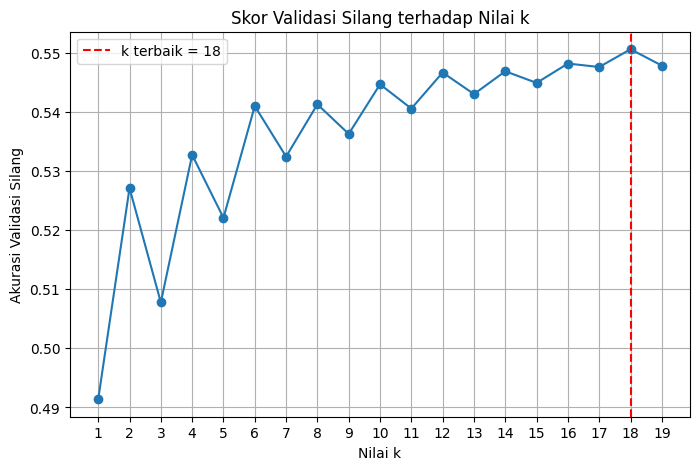

In [41]:
##202431007_Wijdan Zayyan Sururi
skor_cv = grid_knn.cv_results_['mean_test_score']

plt.figure(figsize=(8, 5))
plt.plot(range(1, 20), skor_cv, marker='o')
plt.axvline(k_terbaik, color='red', linestyle='--', label='k terbaik = ' + str(k_terbaik))
plt.title('Skor Validasi Silang terhadap Nilai k')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi Validasi Silang')
plt.xticks(range(1, 20))
plt.grid(True)
plt.legend()
plt.show()

## 4.3 Support Vector Machine (SVM)

In [42]:
##202431007_Wijdan Zayyan Sururi
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC

In [43]:
##202431007_Wijdan Zayyan Sururi
print(df_svm['would_recommend_ai'].unique())
print(df_svm['would_recommend_ai'].value_counts())

# No  = mahasiswa tidak merekomendasikan AI
# Yes = mahasiswa merekomendasikan AI

['No' 'Yes']
would_recommend_ai
Yes    742
No     458
Name: count, dtype: int64


In [44]:
##202431007_Wijdan Zayyan Sururi
le = LabelEncoder()
y_svm = le.fit_transform(df_svm['would_recommend_ai'])
for kode, kelas in enumerate(le.classes_):
    print(kode, '=', kelas)

0 = No
1 = Yes


In [45]:
##202431007_Wijdan Zayyan Sururi
fitur_numerik = ['age', 'year_of_study', 'ai_hours_per_week', 'prompt_skill_level',
                 'ai_assignment_share_pct', 'study_hours_per_week', 'cgpa',
                 'critical_thinking_score', 'time_saved_pct', 'ai_dependency_score',
                 'integrity_concern_level']
fitur_kategori = ['paid_ai_subscription', 'flagged_by_ai_detector']

x_svm = df_svm[fitur_numerik + fitur_kategori].copy()
for kolom in fitur_kategori:
    le_fitur = LabelEncoder()
    x_svm[kolom] = le_fitur.fit_transform(x_svm[kolom])
    print(kolom, le_fitur.classes_)
x_svm.head()

paid_ai_subscription ['No' 'Yes']
flagged_by_ai_detector ['No' 'Yes']


,age,year_of_study,ai_hours_per_week,prompt_skill_level,ai_assignment_share_pct,study_hours_per_week,cgpa,critical_thinking_score,time_saved_pct,ai_dependency_score,integrity_concern_level,paid_ai_subscription,flagged_by_ai_detector
0,20,2,15.2,4,51,13.7,2.88,53,47,8,3,0,1
1,22,2,2.7,3,11,19.8,3.52,84,29,2,3,0,0
2,21,4,2.4,3,11,20.4,2.94,72,20,2,3,0,0
3,22,3,13.8,3,46,18.0,2.70,68,23,6,1,0,0
4,20,1,4.7,2,9,24.8,3.01,62,19,3,1,0,0


In [46]:
##202431007_Wijdan Zayyan Sururi
x_train_svm, x_test_svm, y_train_svm, y_test_svm = train_test_split(
    x_svm, y_svm, test_size=0.3, random_state=0, stratify=y_svm)

print('Data latih:', x_train_svm.shape[0])
print('Data uji  :', x_test_svm.shape[0])
print('Proporsi kelas latih:', np.bincount(y_train_svm) / len(y_train_svm))
print('Proporsi kelas uji  :', np.bincount(y_test_svm) / len(y_test_svm))

Data latih: 840
Data uji  : 360
Proporsi kelas latih: [0.38214286 0.61785714]
Proporsi kelas uji  : [0.38055556 0.61944444]


In [47]:
##202431007_Wijdan Zayyan Sururi
pipeline_svm = Pipeline([('scaler', StandardScaler()),
                         ('svc', SVC())])

In [48]:
##202431007_Wijdan Zayyan Sururi
params_svm = {
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.01, 0.1, 1]
}

jumlah_kombinasi = 1
for nilai in params_svm.values():
    jumlah_kombinasi = jumlah_kombinasi * len(nilai)
print('Jumlah kombinasi:', jumlah_kombinasi)

Jumlah kombinasi: 48


In [49]:
##202431007_Wijdan Zayyan Sururi
grid_svm = GridSearchCV(pipeline_svm, params_svm, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_svm.fit(x_train_svm, y_train_svm)

print('Parameter terbaik   :', grid_svm.best_params_)
print('Skor validasi silang:', round(grid_svm.best_score_, 4))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Parameter terbaik   : {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Skor validasi silang: 0.7476


In [50]:
##202431007_Wijdan Zayyan Sururi
hasil_cv = pd.DataFrame(grid_svm.cv_results_)
peringkat1 = hasil_cv[hasil_cv['rank_test_score'] == 1]

print('Jumlah kandidat peringkat 1:', len(peringkat1))
print(peringkat1[['params', 'mean_test_score', 'std_test_score']].to_string())

Jumlah kandidat peringkat 1: 5
                                                          params  mean_test_score  std_test_score
1   {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}         0.747619        0.013363
4      {'svc__C': 0.1, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}         0.747619        0.012257
8      {'svc__C': 0.1, 'svc__gamma': 0.1, 'svc__kernel': 'poly'}         0.747619        0.010378
28      {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}         0.747619        0.011664
41    {'svc__C': 100, 'svc__gamma': 0.01, 'svc__kernel': 'poly'}         0.747619        0.010378


In [51]:
##202431007_Wijdan Zayyan Sururi
model_svm = grid_svm.best_estimator_
y_train_pred = model_svm.predict(x_train_svm)
y_test_pred = model_svm.predict(x_test_svm)

print('Akurasi latih:', round(accuracy_score(y_train_svm, y_train_pred), 4))
print('Akurasi uji  :', round(accuracy_score(y_test_svm, y_test_pred), 4))
print('Confusion matrix latih:')
print(confusion_matrix(y_train_svm, y_train_pred))
print('Confusion matrix uji:')
print(confusion_matrix(y_test_svm, y_test_pred))
print(classification_report(y_test_svm, y_test_pred, target_names=le.classes_))

Akurasi latih: 0.7476
Akurasi uji  : 0.7306
Confusion matrix latih:
[[111 210]
 [  2 517]]
Confusion matrix uji:
[[ 41  96]
 [  1 222]]
              precision    recall  f1-score   support

          No       0.98      0.30      0.46       137
         Yes       0.70      1.00      0.82       223

    accuracy                           0.73       360
   macro avg       0.84      0.65      0.64       360
weighted avg       0.80      0.73      0.68       360



In [52]:
##202431007_Wijdan Zayyan Sururi
fitur_2d = ['prompt_skill_level', 'time_saved_pct']

scaler_2d = StandardScaler()
x2_train = scaler_2d.fit_transform(x_train_svm[fitur_2d])

for c in [0.01, 0.1, 1, 10]:
    svm_uji = SVC(kernel='linear', C=c)
    svm_uji.fit(x2_train, y_train_svm)
    margin = 2 / np.linalg.norm(svm_uji.coef_[0])
    print('C =', c, '| margin =', round(margin, 4),
          '| support vector =', svm_uji.n_support_.sum(),
          '| akurasi latih =', round(svm_uji.score(x2_train, y_train_svm), 4))

C = 0.01 | margin = 3.0317 | support vector = 560 | akurasi latih = 0.7417
C = 0.1 | margin = 2.8735 | support vector = 522 | akurasi latih = 0.7429
C = 1 | margin = 2.845 | support vector = 517 | akurasi latih = 0.7429
C = 10 | margin = 2.8446 | support vector = 516 | akurasi latih = 0.7429


In [53]:
##202431007_Wijdan Zayyan Sururi
svm_2d = SVC(kernel='linear', C=1)
svm_2d.fit(x2_train, y_train_svm)

print('coef_      :', svm_2d.coef_)
print('intercept_ :', svm_2d.intercept_)
print('n_support_ :', svm_2d.n_support_)
print('margin     :', round(2 / np.linalg.norm(svm_2d.coef_[0]), 4))

coef_      : [[0.66272802 0.23449107]]
intercept_ : [0.71078802]
n_support_ : [258 259]
margin     : 2.845


In [54]:
##202431007_Wijdan Zayyan Sururi
baris = x_test_svm.iloc[[0]]
print(baris.T)

cek_rentang = (baris.iloc[0] >= x_train_svm.min()) & (baris.iloc[0] <= x_train_svm.max())
print('Semua fitur dalam rentang data latih:', cek_rentang.all())
print('Prediksi:', le.inverse_transform(model_svm.predict(baris))[0])
print('Label asli:', le.inverse_transform(y_test_svm[:1])[0])

                            47
age                      18.00
year_of_study             1.00
ai_hours_per_week         4.20
prompt_skill_level        3.00
ai_assignment_share_pct  27.00
study_hours_per_week     16.90
cgpa                      2.95
critical_thinking_score  62.00
time_saved_pct           37.00
ai_dependency_score       3.00
integrity_concern_level   2.00
paid_ai_subscription      1.00
flagged_by_ai_detector    1.00
Semua fitur dalam rentang data latih: True
Prediksi: Yes
Label asli: Yes
